# Model: prijs van een occasion over 1–5 jaar

De voorspelling bestaat uit twee delen:

| Deel | Model | Wat het voorspelt |
|---|---|---|
| **1. Waarde van de auto** | Baseline, Ridge en CatBoost (vergeleken) | prijs uit kenmerken, leeftijd en km, bij het marktniveau van nu |
| **2. Markt** | Time-series-modellen op de CBS-reeks (vergeleken) | hoe het prijsniveau van occasions de komende jaren verandert |

`prijs over n jaar = waarde van de auto (n jaar ouder, meer km) × marktfactor over n jaar`

Alle bedragen zijn in **euro's van 2026** (`price_2026`). Algemene inflatie komt er aan het eind optioneel bij.

**Evaluatie (backtest):** de modellen worden getraind op het verleden en getest op de toekomst, nooit willekeurig:

| Set | Periode | Gebruik |
|---|---|---|
| train | mrt 2023 – jun 2024 | trainen |
| validatie | jul – dec 2024 | hyperparameters kiezen |
| test | 2025 | één keer, aan het eind: **1 jaar vooruit** |

Extra: trainen op alleen 2023 en testen op 2025 (**2 jaar vooruit**).
De data van oktober 2026 wordt pas gebruikt voor het eindmodel.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, FunctionTransformer, PolynomialFeatures
from sklearn.linear_model import Ridge
from catboost import CatBoostRegressor, Pool
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.exponential_smoothing.ets import ETSModel

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", module="statsmodels")

RANDOM_STATE = 42
MAX_BOMEN = 4000   # meer bomen maakt het model nauwelijks beter, wel trager en groter (~19 KB per boom)
START = pd.Timestamp("2023-03-01")   # begin van de data; t = maanden sinds deze datum

## 1. Data en features

- **Doel:** `log(price_2026)`. Auto's verliezen een *percentage* van hun waarde, geen vast bedrag; op log-schaal
  is dat een rechte lijn en tellen goedkope en dure auto's even zwaar mee. Voor de evaluatie rekenen we terug naar euro's.
- `t`: maanden sinds maart 2023, zodat het model het marktniveau per moment kent.
- `geschat`: 1 als de nieuwprijs een schatting is (minder betrouwbaar).
- **Gewicht per maand:** oktober 2026 heeft ~40× zoveel rijen als een Wayback-maand. Met gewichten telt elke maand
  even zwaar, anders bepaalt die ene maand de uitkomst.

In [2]:
d = pd.read_parquet("dataset_tijd.parquet")
cpi = pd.read_csv("cpi.csv", index_col="year")

d["t"] = (d["snapshot_date"] - START).dt.days / 30.44
d["geschat"] = d["new_price_source"].str.startswith("schatting").astype(int)
d["y"] = np.log(d["price_2026"])

d["gewicht"] = 1 / d.groupby("maand")["maand"].transform("size")
d["gewicht"] *= len(d) / d["gewicht"].sum()

CATEGORISCH = ["brand_model", "brand", "fuel_type", "transmission"]
NUMERIEK = ["age", "mileage_km", "new_price_2026", "t", "geschat"]
FEATURES = CATEGORISCH + NUMERIEK

print(d.shape)
d[FEATURES + ["price_2026"]].head()

(266884, 19)


,brand_model,brand,fuel_type,transmission,age,mileage_km,new_price_2026,t,geschat,price_2026
0,Volkswagen Polo,Volkswagen,petrol,automatic,6.708,56332,28513.0,0.0,1,17758.0
1,Volkswagen Polo,Volkswagen,petrol,manual,11.708,78818,26473.0,0.0,1,7741.0
2,Volkswagen Polo,Volkswagen,diesel,manual,8.708,210826,26542.0,0.0,1,8855.0
3,Volkswagen Polo,Volkswagen,petrol,manual,4.708,107775,29252.0,0.0,1,16089.0
4,Volkswagen Polo,Volkswagen,petrol,manual,14.708,77941,26233.0,0.0,1,5902.0


In [3]:
train = d[d["snapshot_date"] < "2024-07-01"]
val = d[(d["snapshot_date"] >= "2024-07-01") & (d["snapshot_date"] < "2025-01-01")]
train_val = d[d["snapshot_date"] < "2025-01-01"]
test = d[d["snapshot_date"].dt.year == 2025]

for naam, deel in [("train", train), ("validatie", val), ("test", test)]:
    print(f"{naam:<10} {deel['maand'].min()} t/m {deel['maand'].max()}  {len(deel):>7,} rijen")

train      2023-03 t/m 2024-06   58,779 rijen
validatie  2024-07 t/m 2024-12   19,535 rijen
test       2025-01 t/m 2025-12   41,564 rijen


In [4]:
def evalueer(naam, log_pred, deel):
    """Fout in euro's van 2026: MAE, mediane procentuele fout en R²."""
    pred = np.exp(log_pred)
    echt = deel["price_2026"].values
    fout = np.abs(pred - echt)
    return {
        "model": naam,
        "MAE (€)": round(fout.mean()),
        "mediane fout": f"{np.median(fout / echt):.1%}",
        "R²": round(1 - np.sum((pred - echt) ** 2) / np.sum((echt - echt.mean()) ** 2), 3),
    }

## 2. Model 1: baseline

Mediane prijs van dezelfde `brand_model` en leeftijd (hele jaren) in de trainingsdata; anders de mediaan van het model;
anders de totale mediaan. Een echt model moet dit duidelijk verslaan.

In [5]:
class Baseline:
    def fit(self, df):
        self.per_leeftijd = df.groupby(self._sleutel(df))["y"].median()
        self.per_model = df.groupby("brand_model")["y"].median()
        self.totaal = df["y"].median()
        return self

    def predict(self, df):
        return (self._sleutel(df).map(self.per_leeftijd)
                .fillna(df["brand_model"].map(self.per_model))
                .fillna(self.totaal).values)

    @staticmethod
    def _sleutel(df):
        return df["brand_model"] + "|" + df["age"].round().astype(int).astype(str)

baseline = Baseline().fit(train)
pd.DataFrame([evalueer("Baseline", baseline.predict(val), val)])

,model,MAE (€),mediane fout,R²
0,Baseline,6524,15.9%,0.874


## 3. Model 2: Ridge-regressie

Lineair model op `log(prijs)`, goed uit te leggen:
- `brand_model`, brandstof en transmissie als one-hot;
- leeftijd als **spline** (de afschrijvingscurve mag elke vorm hebben);
- `log(km)` en `log(nieuwprijs)`;
- een aparte afschrijvingssnelheid per merk en per brandstof (interactie `merk × leeftijd`, `brandstof × leeftijd`);
- `t` lineair: de markttrend.

Optimaliseren: de regularisatie `alpha` kiezen op de validatieset.

In [6]:
def maak_ridge(alpha):
    kolommen = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), ["brand_model", "fuel_type", "transmission"]),
        ("leeftijd", SplineTransformer(n_knots=8, degree=3), ["age"]),
        ("km", FunctionTransformer(np.log1p), ["mileage_km"]),
        ("nieuwprijs", FunctionTransformer(np.log), ["new_price_2026"]),
        ("lineair", "passthrough", ["t", "geschat"]),
        ("leeftijd_x", make_pipeline(
            ColumnTransformer([("o", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), ["brand", "fuel_type"]),
                               ("a", "passthrough", ["age"])]),
            PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)), ["brand", "fuel_type", "age"]),
    ])
    return Pipeline([("kolommen", kolommen), ("ridge", Ridge(alpha=alpha))])

ridge_scores = []
for alpha in [0.1, 1, 10, 100]:
    m = maak_ridge(alpha).fit(train, train["y"], ridge__sample_weight=train["gewicht"])
    ridge_scores.append(evalueer(f"Ridge alpha={alpha}", m.predict(val), val) | {"alpha": alpha})

ridge_scores = pd.DataFrame(ridge_scores)
BESTE_ALPHA = ridge_scores.loc[ridge_scores["MAE (€)"].idxmin(), "alpha"]
print("Beste alpha:", BESTE_ALPHA)
ridge_scores

Beste alpha: 0.1


,model,MAE (€),mediane fout,R²,alpha
0,Ridge alpha=0.1,5151,12.4%,0.908,0.1
1,Ridge alpha=1,5176,12.3%,0.900,1.0
2,Ridge alpha=10,5191,12.3%,0.882,10.0
3,Ridge alpha=100,5387,12.6%,0.857,100.0


## 4. Model 3: CatBoost

Gradient boosting (veel kleine beslisbomen na elkaar). Werkt direct met tekstcategorieën zoals `brand_model`
(648 waarden) en leert zelf combinaties, bijvoorbeeld dat elektrische auto's anders afschrijven dan diesels.

Optimaliseren: een rooster van boomdiepte, leersnelheid en regularisatie, elk getraind op train en beoordeeld op
validatie. **Early stopping** stopt met bomen toevoegen zodra de validatiefout niet meer daalt. Duurt een paar minuten.

Let op: beslisbomen trekken een trend in `t` niet door. Buiten de trainingsperiode voorspellen ze het laatste
marktniveau. De marktverandering komt daarom uit deel 2 (time series).

In [7]:
def pool(df, met_gewicht=True):
    return Pool(df[FEATURES], df["y"], cat_features=CATEGORISCH,
                weight=df["gewicht"] if met_gewicht else None)

ROOSTER = [
    {"depth": 6,  "learning_rate": 0.1,  "l2_leaf_reg": 3},
    {"depth": 8,  "learning_rate": 0.1,  "l2_leaf_reg": 3},
    {"depth": 8,  "learning_rate": 0.05, "l2_leaf_reg": 10},
    {"depth": 10, "learning_rate": 0.05, "l2_leaf_reg": 3},
    {"depth": 10, "learning_rate": 0.05, "l2_leaf_reg": 10},
    {"depth": 10, "learning_rate": 0.1,  "l2_leaf_reg": 10},
]

cat_scores = []
for params in ROOSTER:
    m = CatBoostRegressor(iterations=4000, od_type="Iter", od_wait=100, random_seed=RANDOM_STATE,
                          verbose=0, thread_count=-1, **params)
    m.fit(pool(train), eval_set=pool(val), use_best_model=True)
    cat_scores.append(evalueer(f"CatBoost {params}", m.predict(val[FEATURES]), val)
                      | params | {"iteraties": m.get_best_iteration()})

cat_scores = pd.DataFrame(cat_scores)
beste = cat_scores.loc[cat_scores["MAE (€)"].idxmin()]
BESTE_PARAMS = {k: beste[k] for k in ["depth", "learning_rate", "l2_leaf_reg"]}
BESTE_PARAMS["depth"] = int(BESTE_PARAMS["depth"])
# Bij hertrainen op meer data (train + validatie) iets meer bomen
BESTE_ITERATIES = min(int(beste["iteraties"] * len(train_val) / len(train)), MAX_BOMEN)
print("Beste instellingen:", BESTE_PARAMS, "| iteraties bij hertrainen:", BESTE_ITERATIES)
cat_scores.drop(columns=["depth", "learning_rate", "l2_leaf_reg"])

Beste instellingen: {'depth': 10, 'learning_rate': np.float64(0.05), 'l2_leaf_reg': np.int64(10)} | iteraties bij hertrainen: 3855


,model,MAE (€),mediane fout,R²,iteraties
0,"CatBoost {'depth': 6, 'learning_rate': 0.1, 'l...",4394,10.1%,0.914,1026
1,"CatBoost {'depth': 8, 'learning_rate': 0.1, 'l...",4268,9.8%,0.914,885
2,"CatBoost {'depth': 8, 'learning_rate': 0.05, '...",4197,9.6%,0.914,2624
3,"CatBoost {'depth': 10, 'learning_rate': 0.05, ...",4106,9.4%,0.915,1774
4,"CatBoost {'depth': 10, 'learning_rate': 0.05, ...",4088,9.2%,0.913,2894
5,"CatBoost {'depth': 10, 'learning_rate': 0.1, '...",4179,9.5%,0.914,1014


## 5. Test: 1 jaar vooruit (2025)

Alle modellen opnieuw getraind op **train + validatie** (t/m december 2024) met de gekozen instellingen,
en één keer getest op 2025. Bij CatBoost ook zonder gewichten, om het effect daarvan te zien.

In [8]:
def train_catboost(df, met_gewicht=True, iteraties=None):
    m = CatBoostRegressor(iterations=iteraties or BESTE_ITERATIES, random_seed=RANDOM_STATE,
                          verbose=0, thread_count=-1, **BESTE_PARAMS)
    return m.fit(pool(df, met_gewicht))

baseline_tv = Baseline().fit(train_val)
ridge_tv = maak_ridge(BESTE_ALPHA).fit(train_val, train_val["y"], ridge__sample_weight=train_val["gewicht"])
cat_tv = train_catboost(train_val)
cat_tv_zonder = train_catboost(train_val, met_gewicht=False)

resultaat_1j = pd.DataFrame([
    evalueer("Baseline", baseline_tv.predict(test), test),
    evalueer("Ridge", ridge_tv.predict(test), test),
    evalueer("CatBoost zonder gewichten", cat_tv_zonder.predict(test[FEATURES]), test),
    evalueer("CatBoost met gewichten", cat_tv.predict(test[FEATURES]), test),
])
resultaat_1j

,model,MAE (€),mediane fout,R²
0,Baseline,8587,19.3%,0.786
1,Ridge,5711,13.3%,0.884
2,CatBoost zonder gewichten,4535,10.2%,0.926
3,CatBoost met gewichten,4517,10.2%,0.926


## 6. Test: 2 jaar vooruit

Getraind op **alleen 2023**, getest op 2025. Zo zie je hoeveel de voorspelling verslechtert als je verder vooruit kijkt.

In [9]:
train_2023 = d[d["snapshot_date"].dt.year == 2023]
iteraties_2023 = int(beste["iteraties"] * len(train_2023) / len(train))

resultaat_2j = pd.DataFrame([
    evalueer("Baseline", Baseline().fit(train_2023).predict(test), test),
    evalueer("Ridge", maak_ridge(BESTE_ALPHA).fit(train_2023, train_2023["y"],
                                                  ridge__sample_weight=train_2023["gewicht"]).predict(test), test),
    evalueer("CatBoost", train_catboost(train_2023, iteraties=iteraties_2023).predict(test[FEATURES]), test),
])
resultaat_2j

,model,MAE (€),mediane fout,R²
0,Baseline,12757,29.0%,0.612
1,Ridge,6884,16.0%,0.850
2,CatBoost,5613,13.3%,0.904


Fout per leeftijd en per brandstof (CatBoost, test 2025): waar is het model goed en waar minder?

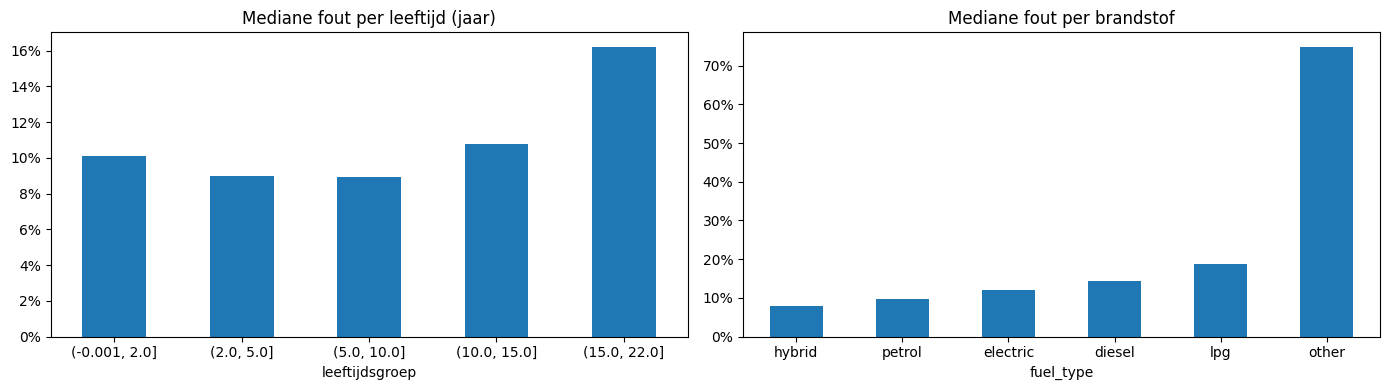

In [10]:
analyse = test.assign(pred=np.exp(cat_tv.predict(test[FEATURES])))
analyse["fout"] = np.abs(analyse["pred"] - analyse["price_2026"]) / analyse["price_2026"]
analyse["leeftijdsgroep"] = pd.cut(analyse["age"], [0, 2, 5, 10, 15, 22], include_lowest=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
analyse.groupby("leeftijdsgroep", observed=True)["fout"].median().plot.bar(ax=axes[0])
axes[0].set_title("Mediane fout per leeftijd (jaar)")
analyse.groupby("fuel_type")["fout"].median().sort_values().plot.bar(ax=axes[1])
axes[1].set_title("Mediane fout per brandstof")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

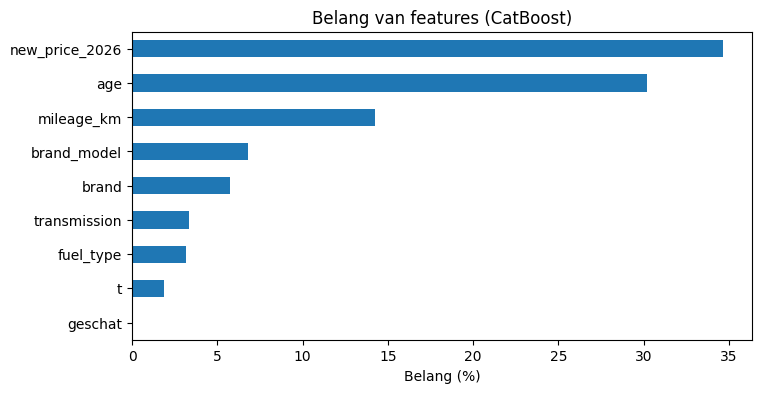

In [11]:
belang = pd.Series(cat_tv.get_feature_importance(), index=FEATURES).sort_values()
belang.plot.barh(figsize=(8, 4), title="Belang van features (CatBoost)")
plt.xlabel("Belang (%)")
plt.show()

## 7. Deel 2: de markt als time series

Hoe verandert het prijsniveau van occasions de komende jaren? Daarvoor is een **lange** reeks nodig.
Onze eigen data beslaat 3,5 jaar; de CBS-index voor tweedehands auto's loopt vanaf 2005.

We gebruiken de **reële** index (`tweedehands / algemene CPI`), want onze prijzen zijn al in euro's van 2026.

### 7a. Eigen marktindex als controle
Een Ridge-regressie met een vaste waarde per maand in plaats van `t`. Die waarden zijn het prijsniveau van
*dezelfde* auto in die maand. Uitkomst ten opzichte van maart 2023 = 100.

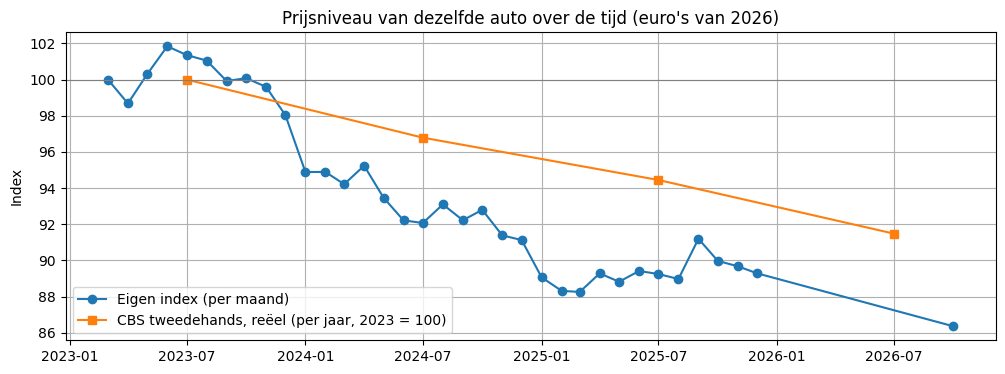

In [12]:
maand_kolommen = ColumnTransformer([
    ("maand", OneHotEncoder(drop=["2023-03"]), ["maand"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), ["brand_model", "fuel_type", "transmission"]),
    ("leeftijd", SplineTransformer(n_knots=8, degree=3), ["age"]),
    ("km", FunctionTransformer(np.log1p), ["mileage_km"]),
    ("nieuwprijs", FunctionTransformer(np.log), ["new_price_2026"]),
])
index_model = Pipeline([("kolommen", maand_kolommen), ("ridge", Ridge(alpha=1))])
index_model.fit(d, d["y"], ridge__sample_weight=d["gewicht"])

maanden = index_model["kolommen"].named_transformers_["maand"].categories_[0]
coef = index_model["ridge"].coef_[: len(maanden) - 1]
eigen_index = pd.Series(100 * np.exp(np.r_[0, coef]), index=maanden)

reeel_cbs = cpi["cpi_used_cars"] / cpi["cpi_all"]
cbs_index = 100 * reeel_cbs / reeel_cbs.loc[2023]

plt.figure(figsize=(12, 4))
plt.plot(pd.PeriodIndex(eigen_index.index, freq="M").to_timestamp(), eigen_index.values, marker="o", label="Eigen index (per maand)")
plt.plot(pd.to_datetime(cbs_index.loc[2023:].index.astype(str)) + pd.DateOffset(months=6), cbs_index.loc[2023:].values,
         marker="s", label="CBS tweedehands, reëel (per jaar, 2023 = 100)")
plt.axhline(100, color="grey", linewidth=0.8)
plt.ylabel("Index")
plt.title("Prijsniveau van dezelfde auto over de tijd (euro's van 2026)")
plt.legend()
plt.grid(True)
plt.show()

### 7b. Time-series-modellen op de CBS-reeks (2005–2025)

Vier modellen, vergeleken met een **rolling backtest**: steeds trainen tot jaar X en de 5 jaar erna voorspellen
(X = 2015 … 2020). Het model met de kleinste fout gebruiken we voor de toekomst.

| Model | Idee |
|---|---|
| Random walk | volgend jaar = dit jaar (markt blijft gelijk) |
| Random walk met drift | gemiddelde jaarlijkse verandering doortrekken |
| ARIMA(1,1,0) | verandering hangt af van de verandering vorig jaar |
| ETS met gedempte trend | trend doortrekken, maar steeds zwakker |

In [13]:
reeks = np.log(reeel_cbs.loc[:2025])
reeks.index = pd.period_range(str(reeks.index[0]), "2025", freq="Y")

TS_MODELLEN = {
    "Random walk": lambda x: ARIMA(x, order=(0, 1, 0)).fit(),
    "Random walk met drift": lambda x: ARIMA(x, order=(0, 1, 0), trend="t").fit(),
    "ARIMA(1,1,0)": lambda x: ARIMA(x, order=(1, 1, 0), trend="t").fit(),
    "ETS gedempte trend": lambda x: ETSModel(x, error="add", trend="add", damped_trend=True).fit(disp=False),
}

ts_scores = {}
for naam, maak in TS_MODELLEN.items():
    fouten = []
    for eind in range(2015, 2021):
        voorspeld = maak(reeks.loc[:str(eind)]).forecast(5)
        echt = reeks.loc[str(eind + 1):str(eind + 5)]
        fouten.append(np.mean(np.abs(np.exp(voorspeld.values[:len(echt)] - echt.values) - 1)))
    ts_scores[naam] = np.mean(fouten)

ts_scores = pd.Series(ts_scores, name="gemiddelde fout (5 jaar vooruit)").sort_values()
BESTE_TS = ts_scores.index[0]
print("Beste time-series-model:", BESTE_TS)
ts_scores.map("{:.1%}".format).to_frame()

Beste time-series-model: ETS gedempte trend


,gemiddelde fout (5 jaar vooruit)
ETS gedempte trend,2.8%
Random walk,3.7%
"ARIMA(1,1,0)",4.5%
Random walk met drift,5.8%


### 7c. Marktfactor voor de komende 5 jaar

Het beste model, getraind op de hele reeks, voorspelt 2026–2031 met een **80%-interval**.
De marktfactor is de verandering ten opzichte van 2026 (het niveau waarop het CatBoost-model voorspelt).
- **midden**: de voorspelling;
- **laag / hoog**: de grenzen van het 80%-interval.

In [14]:
ts_model = TS_MODELLEN[BESTE_TS](reeks)
if BESTE_TS.startswith("ETS"):
    vk = ts_model.get_prediction(start=len(reeks), end=len(reeks) + 5).summary_frame(alpha=0.2)
    vk = vk.rename(columns={"mean": "midden", "pi_lower": "laag", "pi_upper": "hoog"})
else:
    vk = ts_model.get_forecast(6).summary_frame(alpha=0.2)
    vk = vk.rename(columns={"mean": "midden", "mean_ci_lower": "laag", "mean_ci_upper": "hoog"})

vk.index = range(2026, 2032)
basis_2026 = vk.loc[2026, "midden"]
MARKTFACTOR = np.exp(vk[["laag", "midden", "hoog"]] - basis_2026)
MARKTFACTOR.loc[2026] = 1.0
MARKTFACTOR.index = MARKTFACTOR.index - 2026   # 0 = nu, 1 = over een jaar, ...
MARKTFACTOR.index.name = "jaren vooruit"
MARKTFACTOR.round(3)

,laag,midden,hoog
jaren vooruit,,,
0,1.000,1.000,1.000
1,0.961,0.998,1.036
2,0.959,0.996,1.034
3,0.958,0.994,1.032
4,0.956,0.993,1.031
5,0.955,0.992,1.030


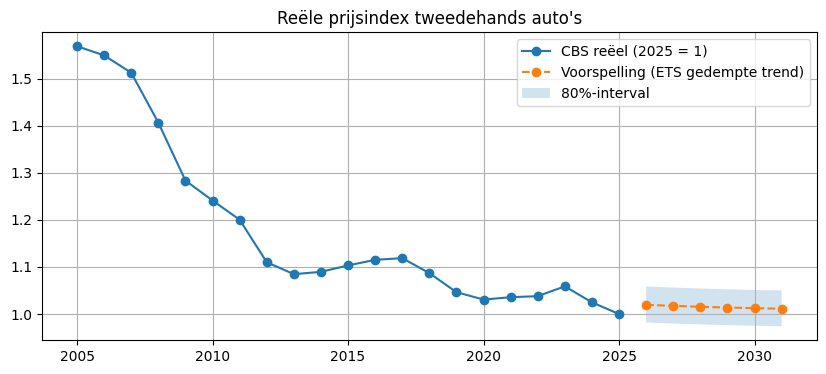

In [15]:
plt.figure(figsize=(10, 4))
verleden = np.exp(reeks - reeks.iloc[-1])
plt.plot(verleden.index.year, verleden.values, marker="o", label="CBS reëel (2025 = 1)")
toekomst = np.exp(vk[["laag", "midden", "hoog"]] - reeks.iloc[-1])
plt.plot(toekomst.index, toekomst["midden"], marker="o", linestyle="--", label=f"Voorspelling ({BESTE_TS})")
plt.fill_between(toekomst.index, toekomst["laag"], toekomst["hoog"], alpha=0.2, label="80%-interval")
plt.title("Reële prijsindex tweedehands auto's")
plt.legend()
plt.grid(True)
plt.show()

## 8. Eindmodel

CatBoost getraind op **alle** data (t/m oktober 2026) met de gekozen instellingen, zodat het de nieuwste prijzen kent.
Maximaal `MAX_BOMEN` bomen: meer bomen leveren bij deze hoeveelheid data nauwelijks iets op, maar maken het
bestand groter (GitHub staat maximaal 100 MB toe) en het trainen trager.

In [16]:
iteraties_alles = min(int(beste["iteraties"] * len(d) / len(train)), MAX_BOMEN)
eindmodel = train_catboost(d, iteraties=iteraties_alles)
eindmodel.save_model("model_catboost.cbm")
T_NU = d["t"].max()
import os
print(f"Getraind op {len(d):,} rijen, {iteraties_alles} bomen. "
      f"Opgeslagen als model_catboost.cbm ({os.path.getsize('model_catboost.cbm') / 1e6:.0f} MB)")

Getraind op 266,884 rijen, 4000 bomen. Opgeslagen als model_catboost.cbm (77 MB)


## 9. Voorspellen: de prijs over 0–5 jaar

1. De auto `n` jaar ouder maken en kilometers erbij tellen.
2. CatBoost voorspelt de prijs bij het marktniveau van nu (euro's van 2026).
3. × de marktfactor (laag / midden / hoog) uit de time series.
4. Optioneel: × `(1 + inflatie) ** n` voor de prijs in euro's van dat jaar.

In [17]:
NU = 2026 + (10 - 0.5) / 12   # oktober 2026

def maak_auto(merk, model, bouwjaar, km, nieuwprijs, brandstof, transmissie, nieuwprijs_geschat=False):
    """Eén auto in het formaat van het model. `nieuwprijs` in euro's van het bouwjaar (catalogusprijs)."""
    return {
        "brand_model": f"{merk} {model}", "brand": merk, "fuel_type": brandstof, "transmission": transmissie,
        "age": max(NU - (bouwjaar + 0.5), 0), "mileage_km": km,
        "new_price_2026": nieuwprijs * cpi.loc[2026, "cpi_all"] / cpi.loc[bouwjaar, "cpi_all"],
        "t": T_NU, "geschat": int(nieuwprijs_geschat),
    }


def voorspel(auto, jaren=5, km_per_jaar=None, inflatie=0.0):
    """Tabel met de verwachte prijs per jaar: laag / midden / hoog."""
    if km_per_jaar is None:
        km_per_jaar = auto["mileage_km"] / auto["age"] if auto["age"] >= 1 else 15_000

    rijen = []
    for n in range(jaren + 1):
        toekomst = dict(auto, age=auto["age"] + n, mileage_km=auto["mileage_km"] + n * km_per_jaar, t=T_NU + 12 * n)
        prijs = np.exp(eindmodel.predict(pd.DataFrame([toekomst])[FEATURES]))[0]
        factor = MARKTFACTOR.loc[n] * (1 + inflatie) ** n
        rijen.append({"jaren": n, "jaar": 2026 + n, "km": round(toekomst["mileage_km"]),
                      **{s: round(prijs * factor[s], -1) for s in ["laag", "midden", "hoog"]}})
    return pd.DataFrame(rijen).set_index("jaren")

VW Golf 2020, 90.000 km
       jaar      km     laag   midden     hoog
jaren                                         
0      2026   90000  16960.0  16960.0  16960.0
1      2027  104305  14570.0  15120.0  15700.0
2      2028  118609  12850.0  13340.0  13850.0
3      2029  132914  11840.0  12290.0  12760.0
4      2030  147219  10670.0  11080.0  11500.0
5      2031  161523   9250.0   9610.0   9970.0 

BMW 320 2018, 140.000 km
       jaar      km     laag   midden     hoog
jaren                                         
0      2026  140000  15900.0  15900.0  15900.0
1      2027  156884  14030.0  14570.0  15120.0
2      2028  173769  12140.0  12610.0  13090.0
3      2029  190653  10510.0  10910.0  11330.0
4      2030  207538   8610.0   8940.0   9280.0
5      2031  224422   7280.0   7560.0   7850.0 

Toyota Yaris 2023, 25.000 km
       jaar     km     laag   midden     hoog
jaren                                        
0      2026  25000  21610.0  21610.0  21610.0
1      2027  32595  19910.0 

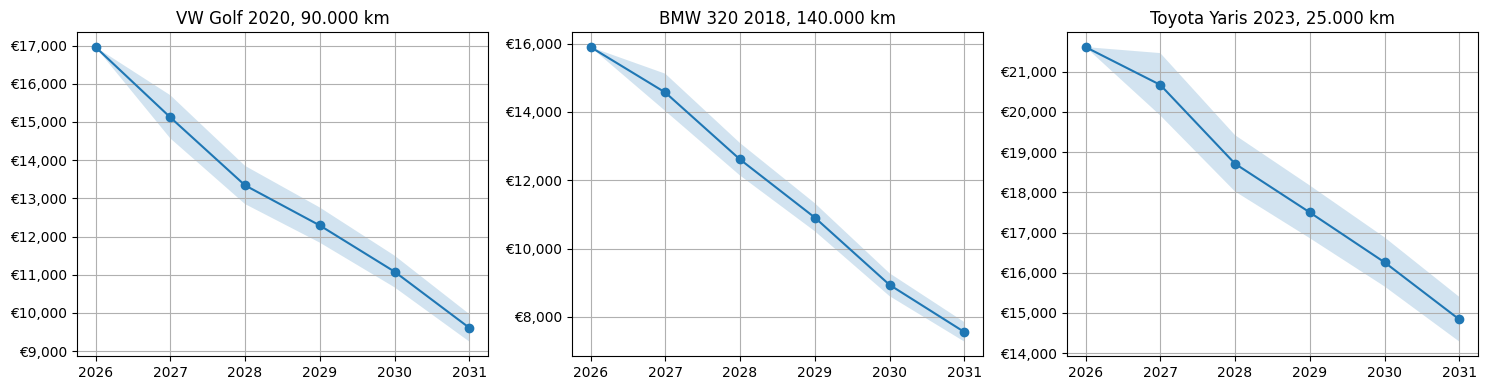

In [18]:
voorbeelden = {
    "VW Golf 2020, 90.000 km": maak_auto("Volkswagen", "Golf", 2020, 90_000, 32_000, "petrol", "manual"),
    "BMW 320 2018, 140.000 km": maak_auto("BMW", "320", 2018, 140_000, 48_000, "diesel", "automatic"),
    "Toyota Yaris 2023, 25.000 km": maak_auto("Toyota", "Yaris", 2023, 25_000, 26_000, "hybrid", "automatic"),
}
fig, axes = plt.subplots(1, len(voorbeelden), figsize=(5 * len(voorbeelden), 4), sharey=False)
for ax, (naam, auto) in zip(axes, voorbeelden.items()):
    tabel = voorspel(auto)
    print(naam)
    print(tabel.to_string(), "\n")
    ax.plot(tabel["jaar"], tabel["midden"], marker="o")
    ax.fill_between(tabel["jaar"], tabel["laag"], tabel["hoog"], alpha=0.2)
    ax.set_title(naam)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"€{v:,.0f}"))
    ax.grid(True)
plt.tight_layout()
plt.show()

Met 2% inflatie per jaar (prijzen in euro's van dat jaar in plaats van euro's van 2026):

In [19]:
voorspel(voorbeelden["VW Golf 2020, 90.000 km"], inflatie=0.02)

,jaar,km,laag,midden,hoog
jaren,,,,,
0,2026,90000,16960.0,16960.0,16960.0
1,2027,104305,14860.0,15430.0,16020.0
2,2028,118609,13370.0,13880.0,14410.0
3,2029,132914,12570.0,13050.0,13550.0
4,2030,147219,11550.0,11990.0,12450.0
5,2031,161523,10210.0,10610.0,11010.0


## Beperkingen (voor het verslag)

- **Getoetst:** 1 en 2 jaar vooruit (secties 5 en 6). **Niet getoetst:** 3–5 jaar. Daar is de bandbreedte een
  onderbouwde schatting, geen getoetste voorspelling.
- **Afschrijving** leert het model uit auto's van verschillende leeftijd; het neemt aan dat een auto over 5 jaar
  evenveel waard is als een vergelijkbare auto die nu 5 jaar ouder is (bij gelijke markt).
- **Markt:** de time series komt uit 21 jaarcijfers van het CBS. Schokken zoals de chiptekorten van 2021–2022
  zijn niet te voorspellen.
- **Vraagprijs ≠ verkoopprijs:** AutoScout24 toont vraagprijzen.
- **Leeftijd benaderd:** alleen het bouwjaar is bekend, niet de registratiemaand.
- **Wayback** is pagina 1 van de zoekresultaten, niet het volledige aanbod.